# Atelier ML - Partie 1 : préparation des données

Objectif : préparer les données du Pokédex et des combats pour pouvoir prédire le vainqueur d'un combat de Pokémons.

## Modules utilisés

- **Pandas** : manipulation et analyse de données

In [18]:
import pandas as pd

pd.set_option('display.max_columns', None)  # Affiche toutes les colonnes
# pd.set_option('future.no_silent_downcasting', True)  # option du cours, obsolète avec pandas 3

## De quelles données disposons-nous ?

On charge le Pokédex dans un Dataframe avec `read_csv`, puis on affiche le nom des colonnes (features).

In [19]:
nosPokemons = pd.read_csv("data/pokedex.csv")

# Affichage des colonnes du Dataframe
print(nosPokemons.columns.values)

<StringArray>
[                 'NUMERO',                     'NOM',
                  'TYPE_1',                  'TYPE_2',
           'POINTS_DE_VIE',          'NIVEAU_ATTAQUE',
          'NIVEAU_DEFENSE', 'NIVEAU_ATTAQUE_SPECIALE',
 'NIVEAU_DEFENSE_SPECIALE',                 'VITESSE',
      'NOMBRE_GENERATIONS',              'LEGENDAIRE']
Length: 12, dtype: str


## Affichage des dix premières lignes

Chaque ligne est une **observation** (un Pokémon) et chaque colonne une **feature** (caractéristique).

In [20]:
print(nosPokemons.head(10))

   NUMERO               NOM TYPE_1  TYPE_2  POINTS_DE_VIE  NIVEAU_ATTAQUE  \
0       1        Bulbizarre  Herbe  Poison             45              49   
1       2        Herbizarre  Herbe  Poison             60              62   
2       3        Florizarre  Herbe  Poison             80              82   
3       4   Mega Florizarre  Herbe  Poison             80             100   
4       5         Salameche    Feu     NaN             39              52   
5       6         Reptincel    Feu     NaN             58              64   
6       7         Dracaufeu    Feu     Vol             78              84   
7       8  Mega Dracaufeu X    Feu  Dragon             78             130   
8       9  Mega Dracaufeu Y    Feu     Vol             78             104   
9      10          Carapuce    Eau     NaN             44              48   

   NIVEAU_DEFENSE  NIVEAU_ATTAQUE_SPECIALE  NIVEAU_DEFENSE_SPECIALE  VITESSE  \
0              49                       65                       65     

## Quelles sont les features de catégorisation ?

Elles permettent de classer les Pokémons dans des groupes :

- **Catégorielles** : `TYPE_1`, `TYPE_2`, `LEGENDAIRE`
- **Ordinale** : `NOMBRE_GENERATIONS` (la génération, une donnée chiffrée)

Ces features ne devront pas être supprimées lors du nettoyage.

## Quelles données sont de type numérique ?

`NUMERO`, `POINTS_DE_VIE`, `NIVEAU_ATTAQUE`, `NIVEAU_DEFENSE`, `NIVEAU_ATTAQUE_SPECIALE`, `NIVEAU_DEFENSE_SPECIALE` et `VITESSE` sont des données **numériques discrètes** (des valeurs entières qu'on peut compter).

## Que faut-il penser de la feature LEGENDAIRE ?

`LEGENDAIRE` contient le texte `VRAI` ou `FAUX`. Le Machine Learning n'utilise que des données numériques : on la transforme donc en `1` (VRAI) ou `0` (FAUX).

In [21]:
# remplacement de VRAI FAUX par 1 0
nosPokemonsClean = nosPokemons
nosPokemonsClean["LEGENDAIRE"] = nosPokemonsClean["LEGENDAIRE"].replace("VRAI", 1)
nosPokemonsClean["LEGENDAIRE"] = nosPokemonsClean["LEGENDAIRE"].replace("FAUX", 0)
nosPokemonsClean["LEGENDAIRE"] = nosPokemonsClean["LEGENDAIRE"].astype(int)
print(nosPokemonsClean.head())

   NUMERO              NOM TYPE_1  TYPE_2  POINTS_DE_VIE  NIVEAU_ATTAQUE  \
0       1       Bulbizarre  Herbe  Poison             45              49   
1       2       Herbizarre  Herbe  Poison             60              62   
2       3       Florizarre  Herbe  Poison             80              82   
3       4  Mega Florizarre  Herbe  Poison             80             100   
4       5        Salameche    Feu     NaN             39              52   

   NIVEAU_DEFENSE  NIVEAU_ATTAQUE_SPECIALE  NIVEAU_DEFENSE_SPECIALE  VITESSE  \
0              49                       65                       65       45   
1              63                       80                       80       60   
2              83                      100                      100       80   
3             123                      122                      120       80   
4              43                       60                       50       65   

   NOMBRE_GENERATIONS  LEGENDAIRE  
0                   1     

## Manque-t-il des données ?

On compte le nombre d'observations et de features avec `shape`.

In [22]:
# Comptage du nombre d'observations et de features
print(nosPokemonsClean.shape)

(800, 12)


La fonction `info()` donne le nombre de valeurs non vides par feature.

In [23]:
# Informations sur notre jeu de données
print(nosPokemonsClean.info())

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   NUMERO                   800 non-null    int64
 1   NOM                      800 non-null    str  
 2   TYPE_1                   800 non-null    str  
 3   TYPE_2                   413 non-null    str  
 4   POINTS_DE_VIE            800 non-null    int64
 5   NIVEAU_ATTAQUE           800 non-null    int64
 6   NIVEAU_DEFENSE           800 non-null    int64
 7   NIVEAU_ATTAQUE_SPECIALE  800 non-null    int64
 8   NIVEAU_DEFENSE_SPECIALE  800 non-null    int64
 9   VITESSE                  800 non-null    int64
 10  NOMBRE_GENERATIONS       800 non-null    int64
 11  LEGENDAIRE               800 non-null    int64
dtypes: int64(9), str(3)
memory usage: 75.1 KB
None


Constats :

- 800 observations et 12 features
- il manque **1 nom** (799 sur 800)
- il manque 387 `TYPE_2` : c'est normal, un Pokémon peut ne pas avoir de type secondaire

## À la recherche des features manquantes

On cherche l'observation dont le nom est vide (`isnull`).

In [24]:
print(nosPokemonsClean[nosPokemonsClean['NOM'].isnull()])

Empty DataFrame
Columns: [NUMERO, NOM, TYPE_1, TYPE_2, POINTS_DE_VIE, NIVEAU_ATTAQUE, NIVEAU_DEFENSE, NIVEAU_ATTAQUE_SPECIALE, NIVEAU_DEFENSE_SPECIALE, VITESSE, NOMBRE_GENERATIONS, LEGENDAIRE]
Index: []


C'est l'observation 62. Les Pokémons sont dans l'ordre du Pokédex : on regarde le Pokémon avant et après pour retrouver le nom manquant dans le [Pokédex](https://www.pokepedia.fr/Liste_des_Pok%C3%A9mon_dans_l%27ordre_du_Pok%C3%A9dex_National).

In [25]:
print(nosPokemonsClean['NOM'][61])
print(nosPokemonsClean['NOM'][63])

Ferosinge
Caninos


Entre Ferosinge et Caninos, le Pokédex indique **Colossinge**.

Le cours utilise `nosPokemonsClean['NOM'][62] = "Colossinge"`, mais avec pandas 3 cette écriture ne modifie plus le Dataframe (le nom reste vide). On utilise `.loc[ligne, colonne]` à la place.

In [26]:
nosPokemonsClean.loc[62, 'NOM'] = "Colossinge"
print(nosPokemonsClean['NOM'][62])

Colossinge


Cette modification ne concerne que le Dataframe. Le fichier `data/pokedex.csv` a aussi été corrigé :

- Avant : `63,,Combat,,65,105,60,60,70,95,1,FAUX`
- Après : `63,Colossinge,Combat,,65,105,60,60,70,95,1,FAUX`

## Place aux observations des combats

Même démarche que pour le Pokédex : chargement, features, dix premières observations, nombre d'observations et données manquantes.

In [27]:
# Chargement des données des combats
combats = pd.read_csv("data/combats.csv")

# Affichage des colonnes du Dataframe
print(combats.columns.values)

# Affichage des 10 premières lignes du Dataframe
print(combats.head(10))

# Comptage du nombre de lignes et de colonnes
print(combats.shape)

# Informations sur notre jeu de données
print(combats.info())

<StringArray>
['Premier_Pokemon', 'Second_Pokemon', 'Pokemon_Gagnant']
Length: 3, dtype: str
   Premier_Pokemon  Second_Pokemon  Pokemon_Gagnant
0              266             298              298
1              702             701              701
2              191             668              668
3              237             683              683
4              151             231              151
5              657             752              657
6              192             134              134
7               73             545              545
8              220             763              763
9              302              31               31
(50000, 3)
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Premier_Pokemon  50000 non-null  int64
 1   Second_Pokemon   50000 non-null  int64
 2   Pokemon_Gagnant  50000 non-null  int64
dtypes:

Constats :

- 50 000 observations (combats) et 3 features : `Premier_Pokemon`, `Second_Pokemon` et `Pokemon_Gagnant`
- `Pokemon_Gagnant` contient le numéro du Pokémon qui a gagné le combat
- toutes les features sont numériques
- il ne manque aucune donnée

## Assemblage des observations

On veut savoir, pour chaque Pokémon, le nombre de combats menés et le nombre de victoires.

### Nombre de combats menés

Un Pokémon peut combattre en première ou en seconde position. Son nombre de combats = nombre de fois en première position + nombre de fois en seconde position.

`groupby()` regroupe les combats par Pokémon et `count()` compte les combats de chaque groupe.

In [28]:
nbFoisPremierePosition = combats.groupby('Premier_Pokemon').count()
print(nbFoisPremierePosition)

                 Second_Pokemon  Pokemon_Gagnant
Premier_Pokemon                                 
1                            70               70
2                            55               55
3                            68               68
4                            62               62
5                            50               50
...                         ...              ...
796                          49               49
797                          64               64
798                          60               60
799                          75               75
800                          61               61

[784 rows x 2 columns]


La première colonne est le critère de regroupement (le numéro du Pokémon). Les deux autres colonnes contiennent la même valeur : le nombre de fois où le Pokémon a combattu en première position.

In [29]:
nbFoisSecondePosition = combats.groupby('Second_Pokemon').count()
print(nbFoisSecondePosition)

                Premier_Pokemon  Pokemon_Gagnant
Second_Pokemon                                  
1                            63               63
2                            66               66
3                            64               64
4                            63               63
5                            62               62
...                         ...              ...
796                          56               56
797                          67               67
798                          59               59
799                          69               69
800                          60               60

[784 rows x 2 columns]


On additionne les deux pour obtenir le nombre total de combats. Avec Pandas, un simple `+` suffit pour additionner les deux tableaux ligne par ligne.

Ne pas tenir compte des noms de colonnes affichés : la colonne qui contient une valeur donne le nombre total de combats (ex. Pokémon 1 : 70 + 63 = 133). Les colonnes `NaN` viennent du fait que les deux tableaux n'ont pas exactement les mêmes noms de colonnes.

In [30]:
nombreTotalDeCombats = nbFoisPremierePosition + nbFoisSecondePosition
print(nombreTotalDeCombats)

                 Pokemon_Gagnant  Premier_Pokemon  Second_Pokemon
Premier_Pokemon                                                  
1                            133              NaN             NaN
2                            121              NaN             NaN
3                            132              NaN             NaN
4                            125              NaN             NaN
5                            112              NaN             NaN
...                          ...              ...             ...
796                          105              NaN             NaN
797                          131              NaN             NaN
798                          119              NaN             NaN
799                          144              NaN             NaN
800                          121              NaN             NaN

[784 rows x 3 columns]


### Nombre de combats gagnés

Même principe en regroupant par `Pokemon_Gagnant`.

In [31]:
nombreDeVictoires = combats.groupby('Pokemon_Gagnant').count()
print(nombreDeVictoires)

                 Premier_Pokemon  Second_Pokemon
Pokemon_Gagnant                                 
1                             37              37
2                             46              46
3                             89              89
4                             70              70
5                             55              55
...                          ...             ...
796                           39              39
797                          116             116
798                           60              60
799                           89              89
800                           75              75

[783 rows x 2 columns]


In [32]:
print(nombreDeVictoires.info())

<class 'pandas.DataFrame'>
Index: 783 entries, 1 to 800
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Premier_Pokemon  783 non-null    int64
 1   Second_Pokemon   783 non-null    int64
dtypes: int64(2)
memory usage: 18.4 KB
None


Seulement **783** Pokémons sur 800 apparaissent dans les victoires : 17 Pokémons n'ont donc jamais gagné de combat.

## Agrégation des données avec le Pokédex

On crée une liste avec, pour chaque Pokémon :

- son numéro (l'index de la liste)
- le nombre de combats menés
- le nombre de combats gagnés
- le pourcentage de victoires

`sort_index()` trie les numéros dans l'ordre croissant, qui est l'ordre du Pokédex.

In [33]:
listeAAgreger = combats.groupby('Pokemon_Gagnant').count()
listeAAgreger.sort_index()

# On ajoute le nombre de combats
listeAAgreger['NBR_COMBATS'] = nbFoisPremierePosition.Pokemon_Gagnant + nbFoisSecondePosition.Pokemon_Gagnant

# On ajoute le nombre de victoires
listeAAgreger['NBR_VICTOIRES'] = nombreDeVictoires.Premier_Pokemon

# On calcule le pourcentage de victoires
listeAAgreger['POURCENTAGE_DE_VICTOIRES'] = nombreDeVictoires.Premier_Pokemon / (nbFoisPremierePosition.Pokemon_Gagnant + nbFoisSecondePosition.Pokemon_Gagnant)

# On affiche la nouvelle liste
print(listeAAgreger)

                 Premier_Pokemon  Second_Pokemon  NBR_COMBATS  NBR_VICTOIRES  \
Pokemon_Gagnant                                                                
1                             37              37          133             37   
2                             46              46          121             46   
3                             89              89          132             89   
4                             70              70          125             70   
5                             55              55          112             55   
...                          ...             ...          ...            ...   
796                           39              39          105             39   
797                          116             116          131            116   
798                           60              60          119             60   
799                           89              89          144             89   
800                           75        

On agrège maintenant cette liste avec le Pokédex grâce à `merge()`. La clé d'agrégation est l'index de la liste (`right_index=True`), relié à la feature `NUMERO` du Pokédex (`left_on='NUMERO'`). Avec `how='left'`, on garde tous les Pokémons du Pokédex, même ceux qui n'ont jamais gagné.

In [34]:
nouveauPokedex = nosPokemonsClean.merge(listeAAgreger, left_on='NUMERO', right_index=True, how='left')
print(nouveauPokedex.describe())

         NUMERO  POINTS_DE_VIE  NIVEAU_ATTAQUE  NIVEAU_DEFENSE  \
count  800.0000     800.000000      800.000000      800.000000   
mean   400.5000      69.258750       79.001250       73.842500   
std    231.0844      25.534669       32.457366       31.183501   
min      1.0000       1.000000        5.000000        5.000000   
25%    200.7500      50.000000       55.000000       50.000000   
50%    400.5000      65.000000       75.000000       70.000000   
75%    600.2500      80.000000      100.000000       90.000000   
max    800.0000     255.000000      190.000000      230.000000   

       NIVEAU_ATTAQUE_SPECIALE  NIVEAU_DEFENSE_SPECIALE     VITESSE  \
count               800.000000               800.000000  800.000000   
mean                 72.820000                71.902500   68.277500   
std                  32.722294                27.828916   29.060474   
min                  10.000000                20.000000    5.000000   
25%                  49.750000                50.0

Le nouveau Dataframe `nouveauPokedex` réunit les caractéristiques de chaque Pokémon et ses résultats en combat : il servira de base aux analyses de la partie 2.

# Atelier ML - Partie 2 : analyse statistique des données

Objectif : déterminer quelles features sont pertinentes pour prédire le vainqueur d'un combat.

## Un peu de statistiques

La fonction `describe()` donne, pour chaque feature numérique :

- `count` : le nombre d'observations
- `mean` : la moyenne
- `std` : l'écart type (la dispersion des valeurs autour de la moyenne)
- `min` et `max` : la plus petite et la plus grande valeur
- `25%`, `50%`, `75%` : les quartiles, qui séparent les observations en quatre groupes égaux

In [35]:
print(nouveauPokedex.describe())

         NUMERO  POINTS_DE_VIE  NIVEAU_ATTAQUE  NIVEAU_DEFENSE  \
count  800.0000     800.000000      800.000000      800.000000   
mean   400.5000      69.258750       79.001250       73.842500   
std    231.0844      25.534669       32.457366       31.183501   
min      1.0000       1.000000        5.000000        5.000000   
25%    200.7500      50.000000       55.000000       50.000000   
50%    400.5000      65.000000       75.000000       70.000000   
75%    600.2500      80.000000      100.000000       90.000000   
max    800.0000     255.000000      190.000000      230.000000   

       NIVEAU_ATTAQUE_SPECIALE  NIVEAU_DEFENSE_SPECIALE     VITESSE  \
count               800.000000               800.000000  800.000000   
mean                 72.820000                71.902500   68.277500   
std                  32.722294                27.828916   29.060474   
min                  10.000000                20.000000    5.000000   
25%                  49.750000                50.0

### Exemple avec NIVEAU_ATTAQUE

- **count = 800** : aucune donnée manquante
- **mean = 79** : en dessous, le niveau d'attaque est faible, au-dessus il est fort
- **std = 32** : les valeurs sont assez éloignées de la moyenne, les niveaux d'attaque sont très variés
- **min = 5, max = 190** : plus le niveau d'attaque est élevé, plus le Pokémon a de chances de gagner
- **quartiles** : 25 % des Pokémons ont une attaque inférieure à 55, 50 % inférieure à 75 et 75 % inférieure à 100. Seulement 25 % dépassent 100 : pour gagner, il vaut mieux choisir un Pokémon de ce dernier quartile.

### Description de notre jeu d'observations

- Les combats se basent sur les données numériques (VITESSE, NIVEAU_ATTAQUE...) : on peut exclure `NOM`, `TYPE_1` et `TYPE_2`.
- `NUMERO` est un identifiant : il n'a aucun lien avec le fait de gagner un combat.
- Certains Pokémons n'ont qu'**un seul point de vie** (`min = 1`) : il faut éviter de les utiliser.
- 25 % des Pokémons ont une **vitesse supérieure à 90** (dernier quartile) : être rapide peut être un avantage.
- L'écart type de `NBR_COMBATS` est de **11**, le plus bas de toutes les features : tous les Pokémons ont mené à peu près le même nombre de combats (proche de la moyenne de 127). Le jeu de données est donc de bonne qualité, aucun Pokémon n'a combattu beaucoup plus que les autres.

## Quels sont les types de Pokémons qu'un dresseur doit posséder ?

Pour maximiser ses chances de gagner, un dresseur doit posséder les Pokémons les plus fréquents : ses adversaires ont de grandes chances d'avoir les mêmes, et deux Pokémons de même type peuvent contrer leurs attaques.

On affiche le nombre de Pokémons par type avec un graphique. On utilise deux modules de visualisation :

- **matplotlib** : création de graphiques
- **seaborn** : graphiques statistiques, construit sur matplotlib

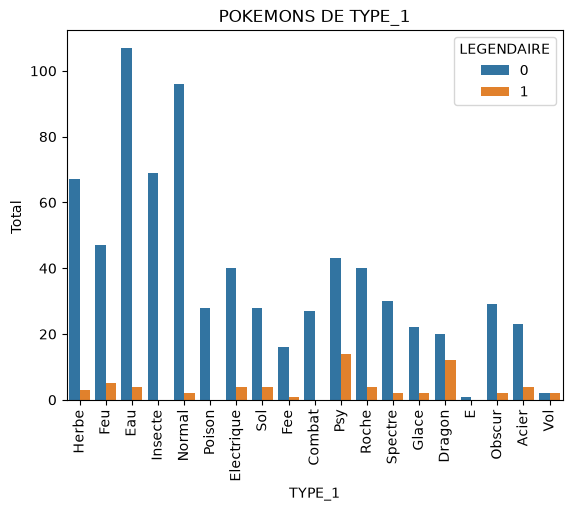

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

axe_X = sns.countplot(x="TYPE_1", hue="LEGENDAIRE", data=nouveauPokedex)
plt.xticks(rotation= 90)
plt.xlabel('TYPE_1')
plt.ylabel('Total ')
plt.title("POKEMONS DE TYPE_1")
plt.show()

Idem pour les Pokémons de type 2 :

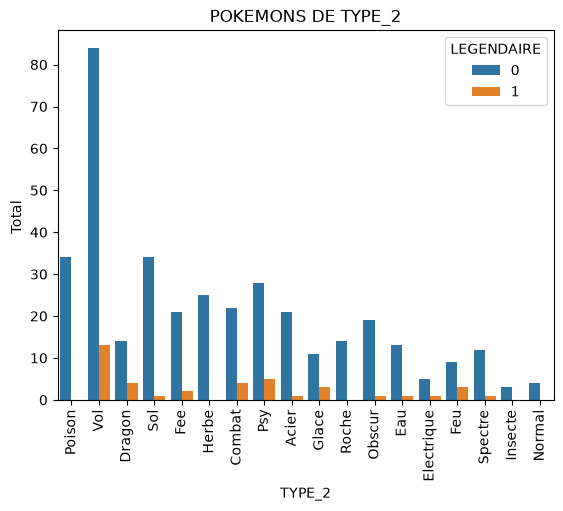

In [37]:
axe_X = sns.countplot(x="TYPE_2", hue="LEGENDAIRE", data=nouveauPokedex)
plt.xticks(rotation= 90)
plt.xlabel('TYPE_2')
plt.ylabel('Total ')
plt.title("POKEMONS DE TYPE_2")
plt.show()

Les barres les plus hautes montrent qu'un dresseur doit posséder des Pokémons de premier type **Eau**, **Normal**, **Herbe** et **Insecte**, puis de second type **Vol**, **Sol** et **Poison** pour pouvoir contrer les attaques.

## Les types de Pokémons gagnants et perdants

On calcule la moyenne des pourcentages de victoires, regroupée par type de Pokémon (`groupby` + `agg`), puis on la trie par ordre croissant (`sort_values`).

In [38]:
print(nouveauPokedex.groupby('TYPE_1').agg({"POURCENTAGE_DE_VICTOIRES": "mean"}).sort_values(by = "POURCENTAGE_DE_VICTOIRES"))

            POURCENTAGE_DE_VICTOIRES
TYPE_1                              
Fee                         0.329300
E                           0.343750
Roche                       0.404852
Acier                       0.424529
Poison                      0.433262
Insecte                     0.439006
Glace                       0.439604
Herbe                       0.440364
Eau                         0.470520
Combat                      0.475616
Spectre                     0.484027
Normal                      0.535578
Sol                         0.541526
Psy                         0.545747
Feu                         0.579215
Obscur                      0.629726
Electrique                  0.632861
Dragon                      0.633587
Vol                         0.765061


Les Pokémons **gagnants** sont de type :

- Vol
- Dragon
- Électrique
- Obscur

Les Pokémons souvent voués à **perdre** sont de type :

- Fée
- Roche
- Acier
- Poison
- Eau (sous la moyenne de 50 %)

Par exemple, Pikachu (type Électrique) a de grandes chances de battre un Pokémon de type Fée.

Le type `E` qui apparaît dans le tableau correspond à un seul Pokémon, Azumarill : c'est une erreur dans le fichier de données (son type devrait être Eau).

## Essayons de trouver une corrélation entre les données

Une corrélation entre deux données signifie qu'elles ont un lien fort entre elles. On cherche les features qui ont un lien fort avec le fait de gagner un combat.

Cette feature peut-elle avoir un impact sur la victoire ?

- `NUMERO` : non, différent pour chaque Pokémon
- `NOM` : non, différent pour chaque Pokémon
- `TYPE_1` : oui, certains types gagnent plus souvent
- `TYPE_2` : non, tous les Pokémons n'ont pas de second type
- `POINTS_DE_VIE` : oui, plus on a de points de vie, plus on a de chances de gagner
- les niveaux (attaque, défense, attaque spéciale, défense spéciale) : oui, ce sont des caractéristiques de combat
- `VITESSE` : oui, c'est aussi une caractéristique de combat
- `LEGENDAIRE` : oui, un Pokémon légendaire aurait une force supplémentaire

Pour visualiser la corrélation, on calcule la corrélation des features (`corr()`) puis on l'affiche dans un graphique **HeatMap**.

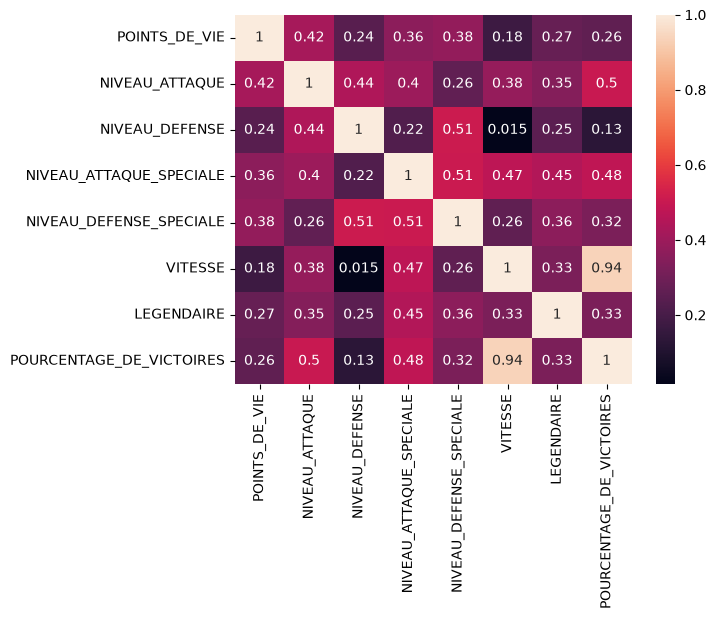

In [39]:
corr = nouveauPokedex.loc[:,['POINTS_DE_VIE','NIVEAU_ATTAQUE',
'NIVEAU_DEFENSE','NIVEAU_ATTAQUE_SPECIALE','NIVEAU_DEFENSE_SPECIALE',
'VITESSE','LEGENDAIRE','POURCENTAGE_DE_VICTOIRES']].corr()

sns.heatmap(corr,
xticklabels=corr.columns,
yticklabels=corr.columns, annot=True)
plt.show()

### Comment lire ce graphique ?

On croise une feature à gauche (axe des ordonnées) avec une feature en bas (axe des abscisses). Le chiffre à l'intersection est le taux de corrélation : plus il est proche de 1, plus la corrélation est forte.

`TYPE_1` n'apparaît pas : ce n'est pas une valeur numérique, elle est donc exclue du calcul.

Pour `POURCENTAGE_DE_VICTOIRES` :

- **VITESSE : 0.94**, la corrélation la plus forte
- **NIVEAU_ATTAQUE : 0.50**
- **LEGENDAIRE : 0.33** seulement, une petite déception car un Pokémon légendaire devait être plus fort

La victoire est donc quasi acquise pour le Pokémon **le plus rapide** des deux, surtout s'il a **un niveau d'attaque supérieur** à son adversaire.

## Résumé de nos observations

Pour remporter la victoire lors d'un combat, le dresseur de Pokémons doit :

- posséder des Pokémons de type **Eau**, **Normal**, **Herbe** et **Insecte**, pour contrer les attaques
- posséder des Pokémons de type **Vol**, **Dragon**, **Électrique** et **Obscur**, qui ont le meilleur taux de victoire
- utiliser un Pokémon ayant une **grande vitesse**
- utiliser un Pokémon ayant un **bon niveau d'attaque**

## Vérifions nos hypothèses

On sélectionne quelques combats du fichier `combats.csv` et on compare la vitesse et le niveau d'attaque des deux Pokémons :

- 155 contre 321
- 101 contre 583
- 404 contre 32

In [40]:
# Les 3 combats sélectionnés
for premier, second in [(155, 321), (101, 583), (404, 32)]:
    print(combats[(combats['Premier_Pokemon'] == premier) & (combats['Second_Pokemon'] == second)])

# Caractéristiques des Pokémons de ces combats
print(nouveauPokedex.loc[nouveauPokedex['NUMERO'].isin([155, 321, 101, 583, 404, 32]),
                         ['NUMERO', 'NOM', 'TYPE_1', 'NIVEAU_ATTAQUE', 'VITESSE']])

       Premier_Pokemon  Second_Pokemon  Pokemon_Gagnant
26905              155             321              155
       Premier_Pokemon  Second_Pokemon  Pokemon_Gagnant
26918              101             583              583
      Premier_Pokemon  Second_Pokemon  Pokemon_Gagnant
9115              404              32               32
     NUMERO         NOM      TYPE_1  NIVEAU_ATTAQUE  VITESSE
31       32      Raichu  Electrique              90      110
100     101    Spectrum     Spectre              50       95
154     155  Mega Ptera       Roche             135      150
320     321    Makuhita      Combat              60       25
403     404    Rosabyss         Eau              84       52
582     583     Zeblitz  Electrique             100      116


| Combat | Vainqueur | Pourquoi |
|---|---|---|
| 155 Méga-Ptéra contre 321 Makuhita | **Méga-Ptéra** | plus rapide (150 contre 25) et meilleure attaque (135 contre 60) |
| 101 Spectrum contre 583 Zéblitz | **Zéblitz** | plus rapide (116 contre 95), meilleure attaque (100 contre 50), type Électrique |
| 404 Rosabyss contre 32 Raichu | **Raichu** | plus rapide (110 contre 52), meilleure attaque (90 contre 84), type Électrique contre Eau |

Dans chaque combat, le Pokémon le plus rapide et le plus fort en attaque a gagné : nos hypothèses semblent vérifiées.

## Sauvegarde du jeu de données

Pour éviter de refaire toute l'analyse et la préparation des données avant chaque apprentissage, on sauvegarde le Dataframe dans `data/dataset.csv`, avec des tabulations comme séparateur (`sep='\t'`). Ce fichier servira dans la partie 3.

In [41]:
#Sauvegarde du Dataframe Pokedex
dataset = nouveauPokedex
dataset.to_csv("data/dataset.csv", sep='\t')